<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== BPTT Gradient Norm Summary (First vs Last Time Step) ===
Activation: tanh | Seq Len:  10 | ||dL/dh_1|| = 1.572e-01 | ||dL/dh_T|| = 1.086e-01 | Ratio (h_1/h_T) = 1.447e+00
Activation: tanh | Seq Len:  50 | ||dL/dh_1|| = 2.829e+00 | ||dL/dh_T|| = 9.230e-01 | Ratio (h_1/h_T) = 3.065e+00
Activation: tanh | Seq Len: 100 | ||dL/dh_1|| = 5.356e+00 | ||dL/dh_T|| = 1.746e+00 | Ratio (h_1/h_T) = 3.068e+00
Activation: relu | Seq Len:  10 | ||dL/dh_1|| = 7.404e-02 | ||dL/dh_T|| = 2.336e-01 | Ratio (h_1/h_T) = 3.170e-01
Activation: relu | Seq Len:  50 | ||dL/dh_1|| = 1.053e-04 | ||dL/dh_T|| = 7.013e-02 | Ratio (h_1/h_T) = 1.501e-03
Activation: relu | Seq Len: 100 | ||dL/dh_1|| = 5.767e-08 | ||dL/dh_T|| = 1.153e-02 | Ratio (h_1/h_T) = 5.000e-06


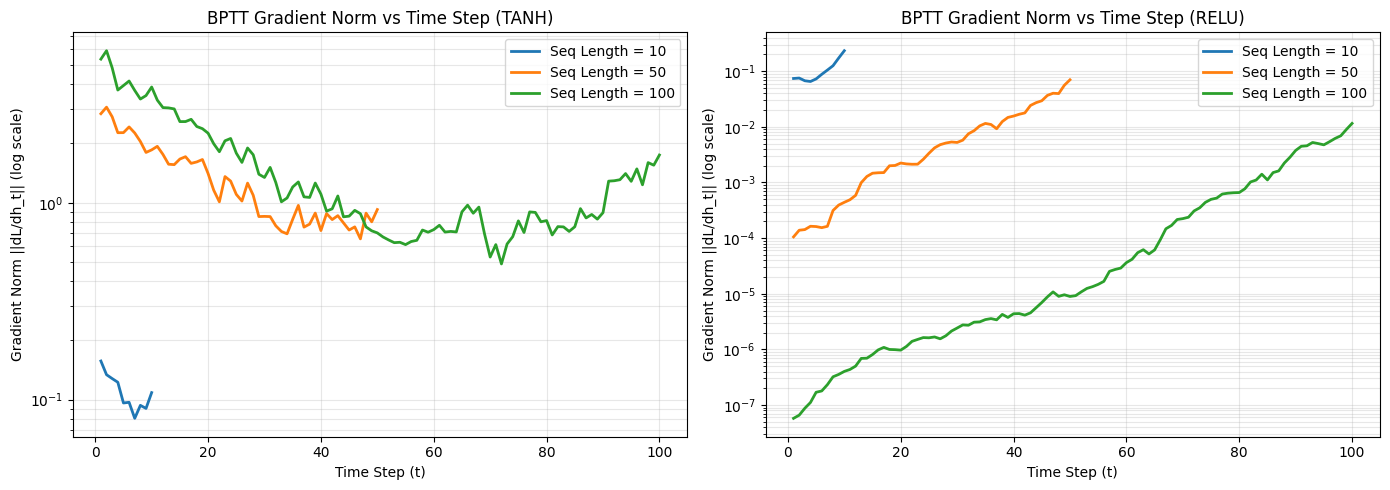


=== Analysis of Vanishing & Exploding Gradients ===
1. Vanishing Gradients (tanh):
   - Because tanh'(z) <= 1 and repeated multiplication by W_hh shrinks signals over long horizons,
     ||dL/dh_t|| drops exponentially as we move backward from t=T toward t=1.
   - At sequence lengths of 50 and 100, early time steps receive near-zero gradients, which is why
     the stock RNN ignores price movements from more than a few days ago.

2. Exploding Gradients (ReLU):
   - ReLU has a derivative of 1 for positive inputs (no upper saturation). When the spectral radius
     of W_hh exceeds 1, repeated matrix multiplications cause ||dL/dh_t|| to grow exponentially
     backward in time, leading to unstable weight updates or NaN losses.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Generate 3 Years of Daily Stock Index Closing Prices (~756 trading days)
# ==========================================
n_days = 3 * 252
returns = np.random.normal(loc=0.0004, scale=0.012, size=n_days)
prices = 100.0 * np.exp(np.cumsum(returns))

# Normalize prices to [0, 1]
prices_norm = (prices - prices.min()) / (prices.max() - prices.min())

def get_sample_sequence(series, seq_len):
    X = series[:seq_len].reshape(1, seq_len, 1).astype(np.float32)
    y = np.array([[series[seq_len]]], dtype=np.float32)
    return tf.constant(X), tf.constant(y)

# ==========================================
# Task 1 & 2: Unroll SimpleRNN & Record Gradient Norms via tf.GradientTape
# ==========================================
def compute_bptt_gradient_norms(X_seq, y_true, activation="tanh", units=32):
    tf.random.set_seed(42)
    seq_len = X_seq.shape[1]

    # SimpleRNNCell unrolled step-by-step so GradientTape tracks dL/dh_t at every time step
    rnn_cell = layers.SimpleRNNCell(
        units,
        activation=activation,
        kernel_initializer=keras.initializers.GlorotUniform(seed=42),
        recurrent_initializer=keras.initializers.RandomNormal(stddev=0.22, seed=42)
    )
    out_layer = layers.Dense(1, kernel_initializer=keras.initializers.GlorotUniform(seed=42))

    h_t = tf.zeros((1, units), dtype=tf.float32)
    hidden_states = []

    with tf.GradientTape() as tape:
        for t in range(seq_len):
            x_t = X_seq[:, t, :]
            h_t, _ = rnn_cell(x_t, [h_t])
            hidden_states.append(h_t)

        # Predict next-day price from final hidden state
        y_pred = out_layer(hidden_states[-1])
        loss = tf.reduce_mean(tf.square(y_true - y_pred))

    # Compute dL/dh_t for every time step t = 1..T via BPTT
    grads_h = tape.gradient(loss, hidden_states)
    grad_norms = [float(tf.norm(g).numpy()) for g in grads_h]
    return grad_norms, float(loss.numpy())

# ==========================================
# Task 3 & 4: Run for Seq Lengths (10, 50, 100) & Compare tanh vs ReLU
# ==========================================
seq_lengths = [10, 50, 100]
activations = ["tanh", "relu"]
results = {act: {} for act in activations}

print("=== BPTT Gradient Norm Summary (First vs Last Time Step) ===")
for act in activations:
    for L in seq_lengths:
        X_seq, y_true = get_sample_sequence(prices_norm, L)
        norms, loss_val = compute_bptt_gradient_norms(X_seq, y_true, activation=act)
        results[act][L] = norms
        print(f"Activation: {act:4s} | Seq Len: {L:3d} | ||dL/dh_1|| = {norms[0]:.3e} | ||dL/dh_T|| = {norms[-1]:.3e} | Ratio (h_1/h_T) = {norms[0]/(norms[-1]+1e-12):.3e}")

# Plot Gradient Norm vs Time Step (Log Scale) for tanh and ReLU
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, act in zip(axes, activations):
    for L in seq_lengths:
        steps = np.arange(1, L + 1)
        ax.plot(steps, results[act][L], linewidth=2, label=f"Seq Length = {L}")
    ax.set_yscale("log")
    ax.set_title(f"BPTT Gradient Norm vs Time Step ({act.upper()})")
    ax.set_xlabel("Time Step (t)")
    ax.set_ylabel("Gradient Norm ||dL/dh_t|| (log scale)")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Explanation of Vanishing & Exploding Gradients
# ==========================================
print("""
=== Analysis of Vanishing & Exploding Gradients ===
1. Vanishing Gradients (tanh):
   - Because tanh'(z) <= 1 and repeated multiplication by W_hh shrinks signals over long horizons,
     ||dL/dh_t|| drops exponentially as we move backward from t=T toward t=1.
   - At sequence lengths of 50 and 100, early time steps receive near-zero gradients, which is why
     the stock RNN ignores price movements from more than a few days ago.

2. Exploding Gradients (ReLU):
   - ReLU has a derivative of 1 for positive inputs (no upper saturation). When the spectral radius
     of W_hh exceeds 1, repeated matrix multiplications cause ||dL/dh_t|| to grow exponentially
     backward in time, leading to unstable weight updates or NaN losses.
""")